In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm
from scipy import stats

file_url = "https://raw.githubusercontent.com/N1tr0Lucas/Trabalho-Big-Data-em-Python/refs/heads/main/data/25-26_SG_INFLU.xlsx"

df = pd.read_excel(file_url, sheet_name="25-26_Influ")



In [51]:

print("Resumo dos dados:")
print(df.info())
print("\nValores unicos por coluna: ")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Resumo dos dados:
<class 'pandas.DataFrame'>
RangeIndex: 280262 entries, 0 to 280261
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   tp_sexo_paciente                 280262 non-null  str           
 1   no_raca_cor_paciente             280262 non-null  str           
 2   co_municipio_paciente            280067 non-null  float64       
 3   no_municipio_paciente            280067 non-null  str           
 4   no_pais_paciente                 280067 non-null  str           
 5   sg_uf_paciente                   280065 non-null  str           
 6   nu_cep_paciente                  267474 non-null  float64       
 7   co_cnes_estabelecimento          280262 non-null  int64         
 8   no_razao_social_estabelecimento  280262 non-null  str           
 9   co_municipio_estabelecimento     280262 non-null  int64         
 10  no_municipio_estabelecimento     2802

In [52]:
df.columns = ["Sexo", "Raca", "Municipio_Codigo", "Municipio", "Pais", "UF_Paciente", "CEP_Paciente", "CNES_Estabelecimento", "Estabelecimento", "Codigo_Municipio_Estabelecimento", "Nome_Municipio_Estabelecimento", "UF_Estabelecimento", "Troca_Documento", "Sigla_Imunobiologico", "Data_Vacina", "Codigo_Vacina", "Tipo_Dose", "Fabricante_Vacina", "Codigo_Grupo_Atendimento", "Nome_Grupo_Atendimento", "Codigo_Categoria", "DS_Categoria", "Codigo_Fabricante", "Nome_Dose", "Idade"]

df.head(10)

,Sexo,Raca,Municipio_Codigo,Municipio,Pais,UF_Paciente,CEP_Paciente,CNES_Estabelecimento,Estabelecimento,Codigo_Municipio_Estabelecimento,...,Codigo_Vacina,Tipo_Dose,Fabricante_Vacina,Codigo_Grupo_Atendimento,Nome_Grupo_Atendimento,Codigo_Categoria,DS_Categoria,Codigo_Fabricante,Nome_Dose,Idade
0,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24474.0,2297205,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",11
1,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24435.0,2291908,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",59
2,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24455.0,2291762,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",19
3,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24715.0,2702959,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",25
4,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24722.0,2708108,PREFEITURA MUNICIPAL DE BARREIRINHA,130050,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",27
5,M,BRANCA,330490.0,SAO GONCALO,BRASIL,RJ,24737.0,2297213,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",1
6,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24473.0,2291983,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",8
7,F,AMARELA,330490.0,SAO GONCALO,BRASIL,RJ,24753.0,2702959,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",56
8,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24456.0,2291819,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,INSTITUTO BUTANTAN,NaN,NaN,NaN,NaN,NaN,"vacina influenza trivalente (fragmentada, inat...",39
9,M,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24716.0,12637,FUNDACAO MUNICIPAL DE SAUDE DE NITEROI,330330,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",2


In [53]:
numericas = ['Idade']
temporais = ['Data_Vacina']
identificadores = ['Municipio_Codigo', 'CEP_Paciente', 'CNES_Estabelecimento',
                   'Codigo_Municipio_Estabelecimento', 'Codigo_Vacina',
                   'Codigo_Grupo_Atendimento', 'Codigo_Categoria', 'Codigo_Fabricante']

def classificar(col):
    if col in numericas: return 'Numérica (quantitativa)'
    if col in temporais: return 'Temporal'
    if col in identificadores: return 'Categórica (código/identificador)'
    return 'Categórica (qualitativa)'

classificacao = pd.DataFrame({
    'Variavel': df.columns,
    'Tipo_pandas': df.dtypes.astype(str).values,
    'Classificacao': [classificar(c) for c in df.columns]
})
print(classificacao.to_string(index=False))

print("\nEstatísticas da variável numérica:")
print(df[numericas].agg(['mean', 'median', 'std', 'min', 'max']).round(2))

                        Variavel    Tipo_pandas                     Classificacao
                            Sexo            str          Categórica (qualitativa)
                            Raca            str          Categórica (qualitativa)
                Municipio_Codigo        float64 Categórica (código/identificador)
                       Municipio            str          Categórica (qualitativa)
                            Pais            str          Categórica (qualitativa)
                     UF_Paciente            str          Categórica (qualitativa)
                    CEP_Paciente        float64 Categórica (código/identificador)
            CNES_Estabelecimento          int64 Categórica (código/identificador)
                 Estabelecimento            str          Categórica (qualitativa)
Codigo_Municipio_Estabelecimento          int64 Categórica (código/identificador)
  Nome_Municipio_Estabelecimento            str          Categórica (qualitativa)
              UF

In [54]:
# 1) Nulos em % (só colunas com nulos)
nulos = pd.DataFrame({'Nulos': df.isnull().sum(),
                      'Percentual': (df.isnull().mean() * 100).round(2)})
print(nulos[nulos['Nulos'] > 0].sort_values('Nulos', ascending=False))

# 2) Tipos incorretos: códigos que viraram float por causa dos nulos
for c in ['Municipio_Codigo', 'CEP_Paciente', 'Codigo_Grupo_Atendimento',
          'Codigo_Categoria', 'Codigo_Fabricante']:
    df[c] = df[c].astype('Int64')   # inteiro que aceita nulo

# 3) Datas futuras (inconsistência)
hoje = pd.Timestamp.today().normalize()
futuras = df['Data_Vacina'] > hoje
print(f"\nRegistros com data futura: {futuras.sum()} (máx.: {df['Data_Vacina'].max().date()})")
df.loc[futuras, 'Data_Vacina'] = pd.NaT   # trata como dado ausente

# 4) Idades implausíveis
print(f"Registros com idade > 110: {(df['Idade'] > 110).sum()} (máx.: {df['Idade'].max()})")

                           Nulos  Percentual
Troca_Documento           279657       99.78
Data_Vacina                44742       15.96
Codigo_Fabricante          24907        8.89
Nome_Grupo_Atendimento     23569        8.41
Codigo_Categoria           23569        8.41
DS_Categoria               23569        8.41
Codigo_Grupo_Atendimento   23237        8.29
CEP_Paciente               12788        4.56
Fabricante_Vacina           1652        0.59
UF_Paciente                  197        0.07
Municipio                    195        0.07
Municipio_Codigo             195        0.07
Pais                         195        0.07

Registros com data futura: 1633 (máx.: 2026-12-09)
Registros com idade > 110: 5 (máx.: 126)


In [55]:
df.describe(include="all")

,Sexo,Raca,Municipio_Codigo,Municipio,Pais,UF_Paciente,CEP_Paciente,CNES_Estabelecimento,Estabelecimento,Codigo_Municipio_Estabelecimento,...,Codigo_Vacina,Tipo_Dose,Fabricante_Vacina,Codigo_Grupo_Atendimento,Nome_Grupo_Atendimento,Codigo_Categoria,DS_Categoria,Codigo_Fabricante,Nome_Dose,Idade
count,280262,280262,280067.0,280067,280067,280065,267474.0,2.802620e+05,280262,280262.000000,...,280262.000000,280262,278610,257025.0,256693,256693.0,256693,255355.0,280262,280262.000000
unique,3,6,<NA>,442,1,24,<NA>,NaN,1828,NaN,...,NaN,6,147,<NA>,86,<NA>,23,<NA>,2,NaN
top,F,SEM INFORMACAO,<NA>,SAO GONCALO,BRASIL,RJ,<NA>,NaN,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,NaN,...,NaN,Única,FUNDACAO BUTANTAN,<NA>,Faixa Etária,<NA>,Faixa Etária,<NA>,"vacina influenza trivalente (fragmentada, inat...",NaN
freq,168565,150742,<NA>,274372,280067,279340,<NA>,NaN,221443,NaN,...,NaN,268087,249683,<NA>,232542,<NA>,232542,<NA>,276735,NaN
mean,NaN,NaN,330444.302424,NaN,NaN,NaN,5495549.273574,3.447493e+06,NaN,330477.391170,...,8.690739,NaN,NaN,363.49666,NaN,2.659574,NaN,207331360.2338,NaN,42.164368
min,NaN,NaN,110002.0,NaN,NaN,NaN,0.0,4.300000e+01,NaN,110004.000000,...,1.000000,NaN,NaN,0.0,NaN,1.0,NaN,142.0,NaN,0.000000
25%,NaN,NaN,330490.0,NaN,NaN,NaN,24451.0,2.291703e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.0,NaN,2.0,NaN,152.0,NaN,17.000000
50%,NaN,NaN,330490.0,NaN,NaN,NaN,24720.0,2.297213e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.0,NaN,2.0,NaN,152.0,NaN,45.000000
75%,NaN,NaN,330490.0,NaN,NaN,NaN,24753.0,4.065417e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.0,NaN,2.0,NaN,152.0,NaN,65.000000
max,NaN,NaN,999999.0,NaN,NaN,NaN,99999999.0,9.996478e+06,NaN,530010.000000,...,38.000000,NaN,NaN,999999.0,NaN,602.0,NaN,10588600000000.0,NaN,126.000000


In [56]:
df.isnull().sum()

Sexo                                     0
Raca                                     0
Municipio_Codigo                       195
Municipio                              195
Pais                                   195
UF_Paciente                            197
CEP_Paciente                         12788
CNES_Estabelecimento                     0
Estabelecimento                          0
Codigo_Municipio_Estabelecimento         0
Nome_Municipio_Estabelecimento           0
UF_Estabelecimento                       0
Troca_Documento                     279657
Sigla_Imunobiologico                     0
Data_Vacina                          46375
Codigo_Vacina                            0
Tipo_Dose                                0
Fabricante_Vacina                     1652
Codigo_Grupo_Atendimento             23237
Nome_Grupo_Atendimento               23569
Codigo_Categoria                     23569
DS_Categoria                         23569
Codigo_Fabricante                    24907
Nome_Dose  

In [57]:
df.duplicated().sum()

np.int64(4153)

In [58]:
df.columns = df.columns.str.strip()

df.duplicated().sum()

df = df.drop_duplicates()

df.isnull().sum().sort_values(ascending=False)

Troca_Documento                     275524
Data_Vacina                          45730
Codigo_Fabricante                    24846
Codigo_Categoria                     23516
Nome_Grupo_Atendimento               23516
DS_Categoria                         23516
Codigo_Grupo_Atendimento             23186
CEP_Paciente                         12486
Fabricante_Vacina                     1644
UF_Paciente                            193
Municipio                              191
Pais                                   191
Municipio_Codigo                       191
Estabelecimento                          0
CNES_Estabelecimento                     0
Raca                                     0
Sexo                                     0
Tipo_Dose                                0
Codigo_Vacina                            0
Sigla_Imunobiologico                     0
UF_Estabelecimento                       0
Codigo_Municipio_Estabelecimento         0
Nome_Municipio_Estabelecimento           0
Nome_Dose  

In [59]:
colunas_interesse = ['Sexo', 'Municipio', 'Idade', 'Nome_Dose', 'Data_Vacina']

df_filtrado = df[colunas_interesse]

df_filtrado.head()

,Sexo,Municipio,Idade,Nome_Dose,Data_Vacina
0,F,SAO GONCALO,11,"vacina influenza trivalente (fragmentada, inat...",2025-01-16
1,F,SAO GONCALO,59,"vacina influenza trivalente (fragmentada, inat...",2025-01-08
2,F,SAO GONCALO,19,"vacina influenza trivalente (fragmentada, inat...",2025-01-12
3,F,SAO GONCALO,25,"vacina influenza trivalente (fragmentada, inat...",2025-01-06
4,F,SAO GONCALO,27,"vacina influenza trivalente (fragmentada, inat...",2025-01-10


In [60]:
df['Nome_Dose'].unique()

<StringArray>
['vacina influenza trivalente (fragmentada, inativada)', 'vacina influenza tetravalente (fragmentada, inativada)']
Length: 2, dtype: str

In [61]:
df['Nome_Dose'].value_counts()

Nome_Dose
vacina influenza trivalente (fragmentada, inativada)      272606
vacina influenza tetravalente (fragmentada, inativada)      3503
Name: count, dtype: int64

Fabricante_Vacina
Instituto Butantan    271101
Nao informado           2299
Abbott                  1403
Sanofi                  1097
GlaxoSmithKline          111
Outros                    44
Fiocruz                   35
Instituto Serum           19
Name: count, dtype: int64


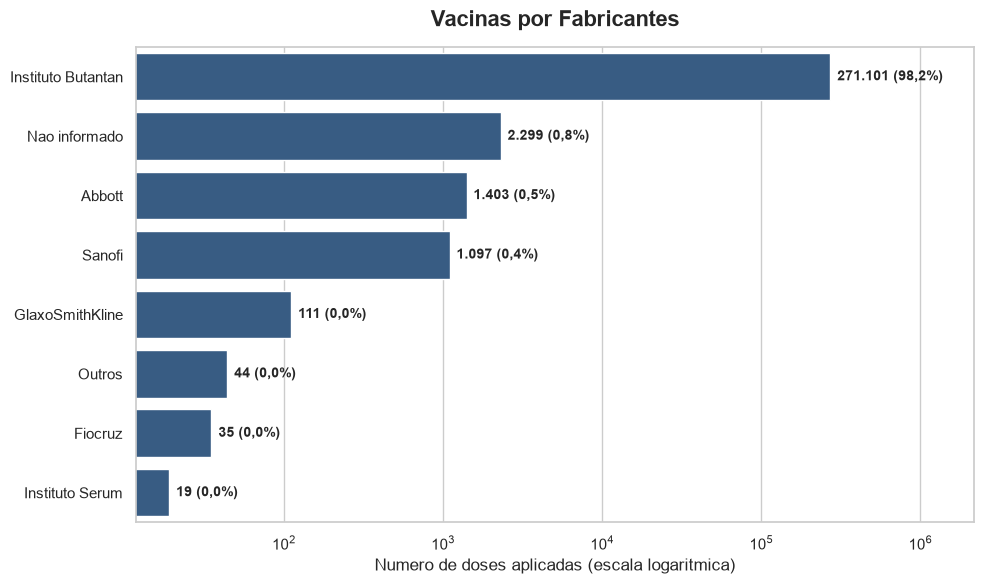

In [62]:
def padronizar_fabricante(valor):
    if pd.isna(valor):
        return 'Nao informado'
    s = unicodedata.normalize('NFKD', valor).encode('ASCII', 'ignore').decode('utf-8').upper()
    s = re.sub(r'[^A-Z0]', '', s)

    if s == '' or re.search(r'PENDENTE|NAOINFORMADO|REGISTRODECART|^INFLUENZA$', s):
        return 'Nao informado'
    if re.search(r'SERUM|SRUM', s):
        return 'Instituto Serum'
    if re.search(r'SANOFI', s):
        return 'Sanofi'
    if re.search(r'ABBOTT', s):
        return 'Abbott'
    if re.search(r'GLAXO', s):
        return 'GlaxoSmithKline'
    if re.search(r'BUT|BUN|BUA|BUB|BTT|ANTAN|INSTITUTO|INSTITUTE|INTITUTO|INSTUTO|INSITUTO|INTISTUTO|FUNDACAO|FUNDAO|^IB$|^INST', s):
        return 'Instituto Butantan'
    if re.search(r'FIO|OSWALDO|MANGUINHOS', s):
        return 'Fiocruz'
    return 'Outros'

df['Fabricante_Vacina'] = df['Fabricante_Vacina'].apply(padronizar_fabricante)

contagem = df['Fabricante_Vacina'].value_counts()
print(contagem)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=contagem.values, y=contagem.index, ax=ax, color='#2b5c8f')
ax.set_xscale('log')

total = contagem.sum()
for p, v in zip(ax.patches, contagem.values):
    texto = f'{v:,} ({v / total * 100:.1f}%)'
    texto = texto.replace(',', 'X').replace('.', ',').replace('X', '.')   
    ax.annotate(texto, (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords='offset points',
                va='center', fontsize=10, fontweight='bold')


ax.set_xlim(right=contagem.max() * 8)

ax.set_title('Vacinas por Fabricantes', fontsize=16, fontweight='bold', pad=15)

ax.set_xlabel('Numero de doses aplicadas (escala logaritmica)', fontsize=12)

ax.set_ylabel('')

plt.tight_layout()

plt.savefig('vacinas_por_fabricantes.png', dpi=300)

plt.show()


In [63]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
Index: 276109 entries, 0 to 280261
Data columns (total 25 columns):
 #   Column                            Non-Null Count   Dtype         
---  ------                            --------------   -----         
 0   Sexo                              276109 non-null  str           
 1   Raca                              276109 non-null  str           
 2   Municipio_Codigo                  275918 non-null  Int64         
 3   Municipio                         275918 non-null  str           
 4   Pais                              275918 non-null  str           
 5   UF_Paciente                       275916 non-null  str           
 6   CEP_Paciente                      263623 non-null  Int64         
 7   CNES_Estabelecimento              276109 non-null  int64         
 8   Estabelecimento                   276109 non-null  str           
 9   Codigo_Municipio_Estabelecimento  276109 non-null  int64         
 10  Nome_Municipio_Estabelecimento    276109 non-nul

In [64]:
print("\nIntervalo de dados para dt_vacina:")
df['Data_Vacina'] = pd.to_datetime(df['Data_Vacina'], errors='coerce')
print(df['Data_Vacina'].min(), "to", df['Data_Vacina'].max())

# Group by date to get daily vaccination count
daily_vac = df.groupby(df['Data_Vacina'].dt.date).size().reset_index(name='total_vacinas')
print("\nResumo diario de vacinacoes:")
print(daily_vac.describe())
print(daily_vac.head(100))



Intervalo de dados para dt_vacina:
2025-01-02 00:00:00 to 2026-10-09 00:00:00

Resumo diario de vacinacoes:
       total_vacinas
count     312.000000
mean      738.394231
std      1307.442225
min         1.000000
25%        14.000000
50%       193.500000
75%       785.500000
max     14266.000000
   Data_Vacina  total_vacinas
0   2025-01-02             70
1   2025-01-03             78
2   2025-01-04              5
3   2025-01-05              5
4   2025-01-06            152
..         ...            ...
95  2025-04-21             12
96  2025-04-22             91
97  2025-04-23            100
98  2025-04-24           1749
99  2025-04-25           2054

[100 rows x 2 columns]


In [65]:
df['Idade'] = df['Idade'].astype(int, errors='ignore')
print("\n---Resumo Idade---")
print(df['Idade'].describe())


---Resumo Idade---
count    276109.000000
mean         42.222477
std          26.180451
min           0.000000
25%          17.000000
50%          45.000000
75%          65.000000
max         126.000000
Name: Idade, dtype: float64


In [66]:
df['Sexo'] = df['Sexo'].astype(str)
print("\n---Distribuicao por Sexo---")
print(df['Sexo'].value_counts(normalize=True)*100)


---Distribuicao por Sexo---
Sexo
F    60.154142
M    39.841874
I     0.003984
Name: proportion, dtype: float64


In [67]:
print("\n---Distribuicao por Dose---:")
print(df['Nome_Dose'].value_counts(normalize=True)*100)


---Distribuicao por Dose---:
Nome_Dose
vacina influenza trivalente (fragmentada, inativada)      98.731298
vacina influenza tetravalente (fragmentada, inativada)     1.268702
Name: proportion, dtype: float64


Sexo
F    166091
M    110007
I        11
Name: count, dtype: int64


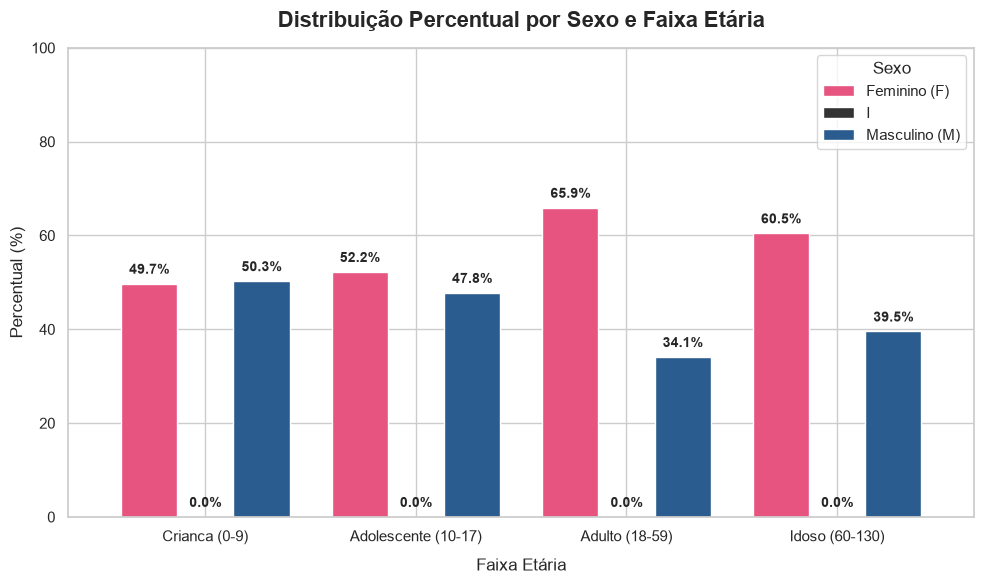

In [68]:
bins = [0, 10, 18, 60, 130]

labels = ['Crianca (0-9)', 'Adolescente (10-17)', 'Adulto (18-59)', 'Idoso (60-130)']
df['Faixa_Etaria'] = pd.cut(df['Idade'], bins=bins, labels=labels, right=False)

df['Sexo'] = df['Sexo'].astype(str).str.strip().str.upper().str[0]
print(df['Sexo'].value_counts(dropna=False))

tabela_cruzada = pd.crosstab(df['Faixa_Etaria'], df['Sexo'], normalize='index') * 100

cores = {'F': '#e75480', 'M': '#2b5c8f'}
nomes = {'F': 'Feminino (F)', 'M': 'Masculino (M)'}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

tabela_cruzada.plot(
    kind='bar', ax=ax, width=0.8, color=[cores.get(c, '#333333') for c in tabela_cruzada.columns]
)

ax.set_title('Distribuição Percentual por Sexo e Faixa Etária', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Faixa Etária', fontsize=12, labelpad=10)
ax.set_ylabel('Percentual (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=0, labelsize=11)
ax.legend([nomes.get(c,c) for c in tabela_cruzada.columns], title='Sexo', frameon=True, facecolor='white')   

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2, h + 1.5),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')
        
plt.tight_layout()

plt.savefig('distribuicao_sexo_faixa_etaria.png', dpi=300)

plt.show()           
        
#print("\n---Perfil por Faixa Etaria e Sexo---")
#print(tabela_cruzada)

Intercepto: 4159.38
Coeficiente (Idade): -29.95
R²: 0.410
                            OLS Regression Results                            
Dep. Variable:              Vacinados   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     75.02
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           5.03e-14
Time:                        19:41:42   Log-Likelihood:                -934.07
No. Observations:                 110   AIC:                             1872.
Df Residuals:                     108   BIC:                             1878.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

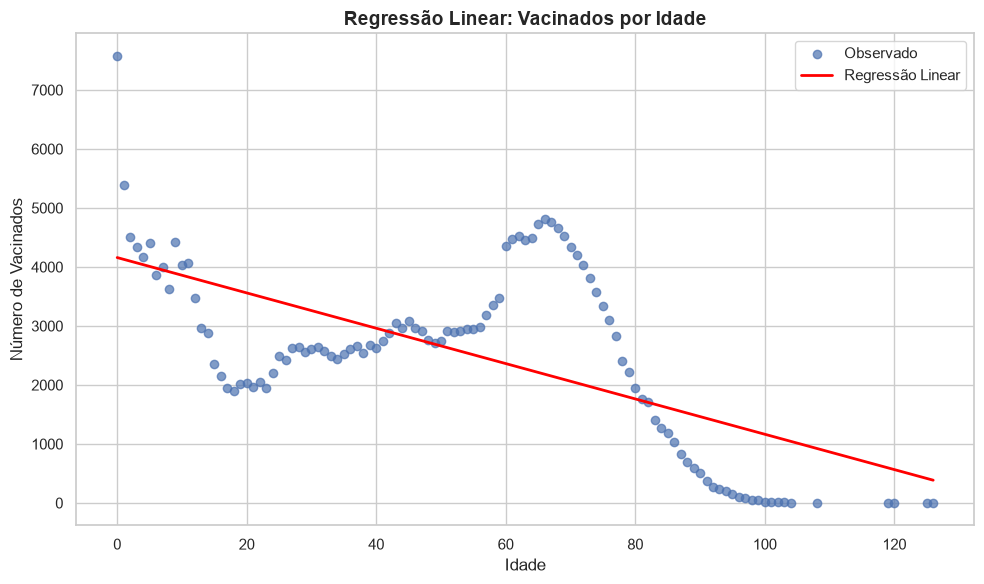

In [69]:
#REGRESSAO LINEAR 

dados = (df['Idade'] .value_counts() .sort_index() .rename_axis('Idade') .reset_index(name='Vacinados'))

x = dados[['Idade']]

y = dados['Vacinados']

#--------------------------------------------------

modelo = LinearRegression()

modelo.fit(x, y)

ypred = modelo.predict(x)

print(f"Intercepto: {modelo.intercept_:.2f}")

print(f"Coeficiente (Idade): {modelo.coef_[0]:.2f}")

print(f"R²: {r2_score(y, ypred):.3f}")

#--------------------------------------------------

X_sm = sm.add_constant(x)
ols = sm.OLS(y, X_sm).fit()
print(ols.summary())

#--------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(dados['Idade'], y, alpha=0.7, label='Observado')

ax.plot(dados['Idade'], ypred, color='red', linewidth=2, label='Regressão Linear')

ax.set_title('Regressão Linear: Vacinados por Idade', fontsize=14, fontweight='bold')

ax.set_xlabel('Idade')

ax.set_ylabel('Número de Vacinados')

ax.legend()

plt.tight_layout()

plt.savefig('regressao_linear_vacinados_idade.png', dpi=300)

plt.show()

In [70]:
def regressao_por_data (df, coluna_data, inicio=None, fim=None, freq='W', titulo=''):

    datas= pd.to_datetime(df[coluna_data], errors='coerce') .dropna()

    datas = datas[datas <= pd.Timestamp.today()]
    if inicio:
        datas = datas[datas >= pd.Timestamp(inicio)]
    if fim:
        datas = datas[datas <= pd.Timestamp(fim)]

    serie = pd.Series(1, index=datas).sort_index().resample(freq).sum()

    dados = serie.reset_index()

    dados.columns = ['Data', 'Vacinados']

    dados['Periodo'] = np.arange(len(dados))

    X = dados[['Periodo']]

    y= dados['Vacinados']

    modelo = LinearRegression().fit(X,y)

    y_pred = modelo.predict(X)

    res = stats.linregress(dados['Periodo'], y)

    unidade = 'semana' if freq == 'W' else 'dia'

    print(f"Periodos analisados: {len(dados)}")

    print(f"Coeficiente: {modelo.coef_[0]:.2f}")

    print(f"Intercepto: {modelo.intercept_:.2f}")

    print(f"R²: {r2_score(y, y_pred):.3f} | p-valor: {res.pvalue:.2e}")



    fig, ax = plt.subplots(figsize=(11, 6))

    ax.scatter(dados['Data'], y, alpha=0.7, label='Observado')

    ax.plot(dados['Data'], y_pred, color='red', linewidth=2, label='Reta de regressão')

    ax.set_title(titulo or 'Regressão Linear: Vacinados por Data', fontsize=14, fontweight='bold')

    ax.set_xlabel('Data')

    ax.set_ylabel(f'Nº de vacinados por {unidade}')

    ax.legend()

    plt.tight_layout()

    plt.show()
    
    return dados, modelo

Periodos analisados: 27
Coeficiente: -598.26
Intercepto: 15242.03
R²: 0.467 | p-valor: 8.49e-05


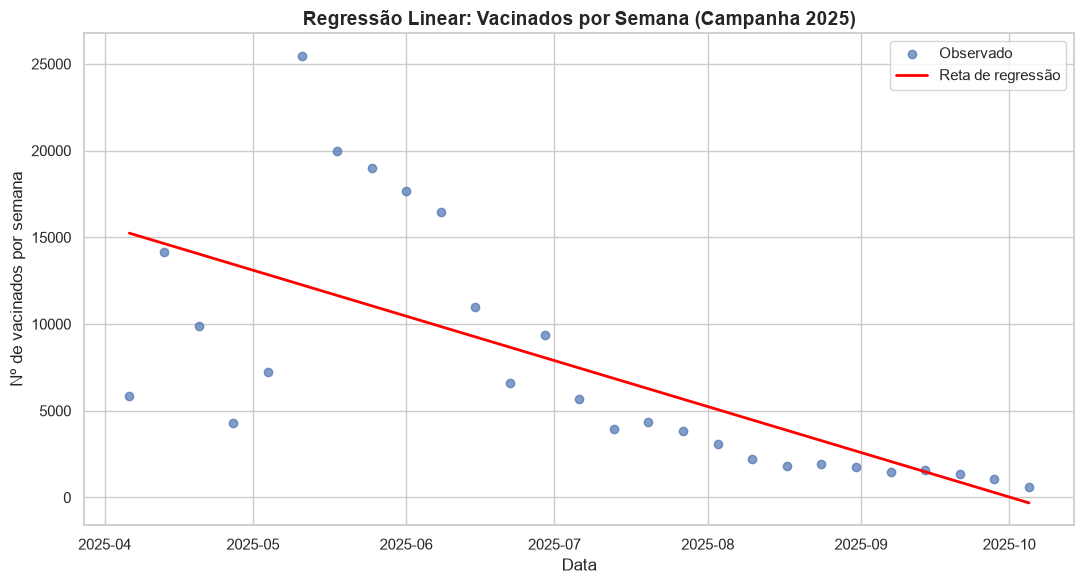

In [71]:
dados_data, modelo_data = regressao_por_data(
    df, 'Data_Vacina',    
    inicio='2025-04-01', fim='2025-09-30',
    titulo='Regressão Linear: Vacinados por Semana (Campanha 2025)'
)

In [72]:
coef = modelo_data.coef_[0]
r2 = modelo_data.score(dados_data[['Periodo']], dados_data['Vacinados'])
print(f"Tendência: {'crescimento' if coef > 0 else 'queda'} de {abs(coef):.1f} vacinados por semana")
print(f"A reta explica {r2*100:.1f}% da variação do número de vacinados")

Tendência: queda de 598.3 vacinados por semana
A reta explica 46.7% da variação do número de vacinados


Semana do pico: 2025-05-11
Periodos analisados: 21
Coeficiente: -931.06
Intercepto: 15720.99
R²: 0.791 | p-valor: 6.94e-08


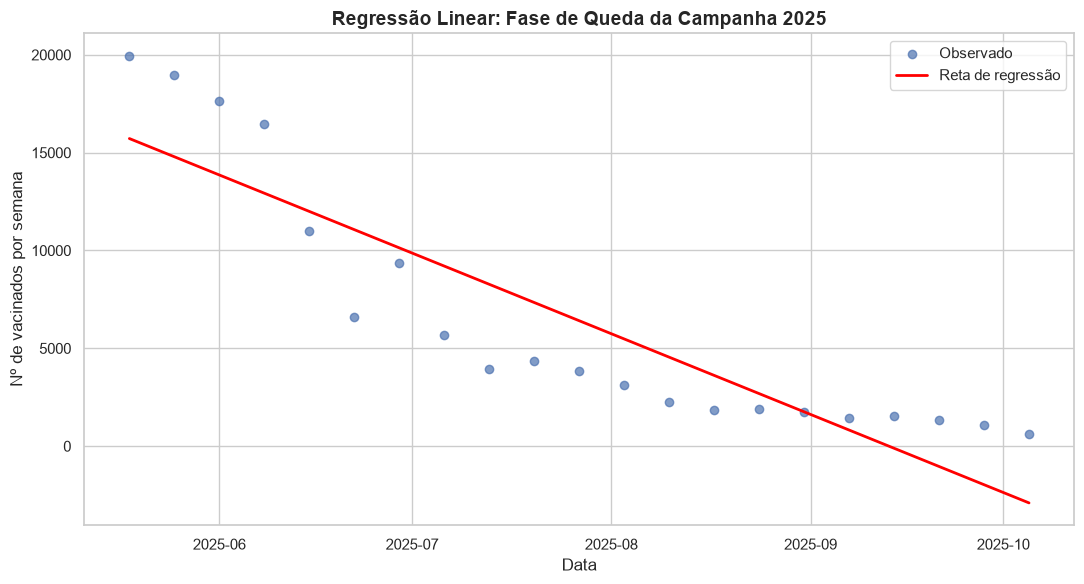

In [73]:
semana_pico = dados_data.loc[dados_data['Vacinados'].idxmax(), 'Data']
print("Semana do pico:", semana_pico.date())

dados_queda, modelo_queda = regressao_por_data(
    df, 'Data_Vacina',
    inicio=semana_pico + pd.Timedelta(days=1), fim='2025-09-30',
    titulo='Regressão Linear: Fase de Queda da Campanha 2025'
)

IQR: limites [-55, 137] -> 0 outliers
Z-score > 3: 3 outliers (idade minima: 125)


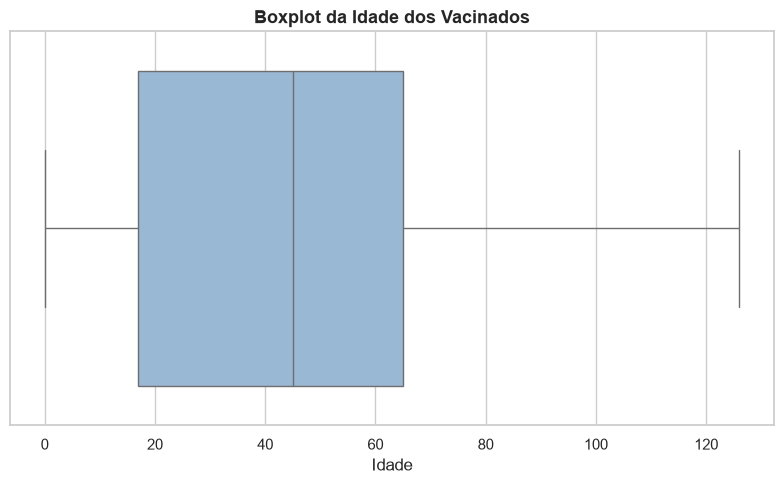


Dias atípicos: 50 de 312
Data_Vacina
2025-05-10    14266
2025-05-20     4277
2025-05-13     4162
2025-05-14     3948
2025-05-16     3845
dtype: int64


In [74]:
idade = df['Idade']

q1, q3 = idade.quantile([0.25, 0.75])

iqr = q3 - q1

lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers_iqr = df[(idade < lim_inf) | (idade > lim_sup)]

z = np.abs(stats.zscore(idade))
outliers_z = df[z > 3]

print(f"IQR: limites [{lim_inf:.0f}, {lim_sup:.0f}] -> {len(outliers_iqr)} outliers")
print(f"Z-score > 3: {len(outliers_z)} outliers (idade minima: {outliers_z["Idade"].min()})")

#------------------------------------------------------------------------------------------------------#

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x=idade, ax=ax, color="#8fb8de")
ax.set_title("Boxplot da Idade dos Vacinados", fontsize=13, fontweight="bold")
ax.set_xlabel("Idade")
plt.tight_layout()
plt.savefig('boxplot_idade.png', dpi=300)
plt.show()

#------------------------------------------------------------------------------------------------------#

d = df.dropna(subset=['Data_Vacina'])
d = d[d['Data_Vacina'] <= pd.Timestamp.today()]          
por_dia = d.groupby('Data_Vacina').size()

q1, q3 = por_dia.quantile([0.25, 0.75])
lim_sup_dia = q3 + 1.5 * (q3 - q1)
dias_outlier = por_dia[por_dia > lim_sup_dia].sort_values(ascending=False)
print(f"\nDias atípicos: {len(dias_outlier)} de {len(por_dia)}")
print(dias_outlier.head())

In [75]:
d = df.dropna(subset=['Data_Vacina'])
d = d[d['Data_Vacina'] <= pd.Timestamp.today()]          
por_dia = d.groupby('Data_Vacina').size()

q1, q3 = por_dia.quantile([0.25, 0.75])
lim_sup_dia = q3 + 1.5 * (q3 - q1)
dias_outlier = por_dia[por_dia > lim_sup_dia].sort_values(ascending=False)
print(f"\nDias atípicos: {len(dias_outlier)} de {len(por_dia)}")
print(dias_outlier.head())


Dias atípicos: 50 de 312
Data_Vacina
2025-05-10    14266
2025-05-20     4277
2025-05-13     4162
2025-05-14     3948
2025-05-16     3845
dtype: int64


In [76]:
dados = (idade.value_counts().sort_index()
         .rename_axis('Idade').reset_index(name='Vacinados'))
modelo = LinearRegression().fit(dados[['Idade']], dados['Vacinados'])
dados['Residuo'] = dados['Vacinados'] - modelo.predict(dados[['Idade']])
dados['Z_res'] = (dados['Residuo'] - dados['Residuo'].mean()) / dados['Residuo'].std()
print("\nIdades com resíduo atípico (|z| > 2):")
print(dados[dados['Z_res'].abs() > 2])


Idades com resíduo atípico (|z| > 2):
    Idade  Vacinados      Residuo     Z_res
0       0       7581  3421.615099  2.888383
65     65       4733  2520.217450  2.127461
66     66       4807  2624.165178  2.215209
67     67       4759  2606.112907  2.199970
68     68       4662  2539.060635  2.143368
69     69       4521  2428.008364  2.049622
